# 04 - M3: PhoBERT fine-tuning (+ extra Vietnamese encoders)
`vinai/phobert-base-v2` + independent sigmoid head, BCE loss (as in the brief). Input: normalised text,
emoji -> Vietnamese description, VnCoreNLP RDRSegmenter word segmentation. Layer-wise LR decay, label-prior
bias init, length-grouped dynamic padding, best epoch selected on validation Macro-F1 @ tau=0.5.

Extra models for the best result: ViSoBERT, ViSoBERT-14GB (raw emoji), CafeBERT / PhoBERT-large (GPU).

In [1]:
# ---- Setup: works both locally and on Google Colab --------------------------------
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # EDIT: folder on your Drive that contains src/, configs/, resources/ and data/{train,val,test}.csv
    PROJECT_DIR = "/content/drive/MyDrive/vigoemotions_midterm"
    os.chdir(PROJECT_DIR)
    subprocess.run("pip -q install -r requirements-colab.txt", shell=True, check=True)
    # Java is needed by VnCoreNLP (PhoBERT word segmentation); falls back to pyvi otherwise
    if subprocess.run("java -version", shell=True, capture_output=True).returncode != 0:
        subprocess.run("apt-get -qq install -y default-jre-headless > /dev/null", shell=True)
else:
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
os.environ["PYTHONPATH"] = os.path.abspath("src") + os.pathsep + os.environ.get("PYTHONPATH", "")
print("project dir:", os.getcwd())

import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
T = lambda name: pd.read_csv(f"results/tables/{name}")          # noqa: E731
F = lambda name, w=900: display(Image(f"results/figures/{name}", width=w))  # noqa: E731

project dir: /Users/tam/Documents/projects/ATI/midterm


In [2]:
RUNS = ["phobert", "visobert", "visobert14gb"]   # add "cafebert", "phobert_large" on a large GPU
for r in RUNS:
    if not os.path.exists(f"results/runs/{r}/summary.json"):
        !python -m vigo train-transformer --config configs/{r}.yaml

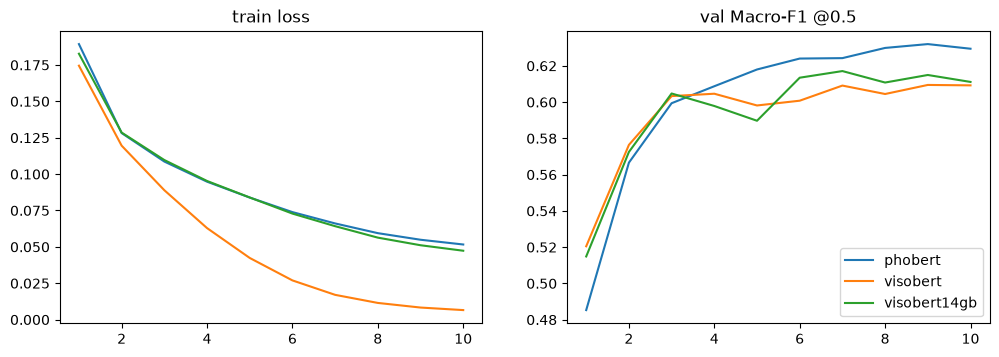

,run,best_epoch,params,train_time_s,val_macro_f1,test_macro_f1,test_micro_f1
0,phobert,9,134429212,3060.179867,0.631987,0.629157,0.646106
1,visobert,9,96996892,2467.976957,0.609459,0.613289,0.631634
2,visobert14gb,7,96996892,2511.310415,0.617106,0.620369,0.642303


In [3]:
import json, matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
rows = []
for r in RUNS:
    p = f"results/runs/{r}/history.csv"
    if not os.path.exists(p):
        continue
    h = pd.read_csv(p)
    ax[0].plot(h.epoch, h.train_loss, label=r)
    ax[1].plot(h.epoch, h.val_macro_f1, label=r)
    s = json.load(open(f"results/runs/{r}/summary.json"))
    rows.append({"run": r, "best_epoch": s.get("best_epoch"), "params": s["total_params"], "train_time_s": s["train_time_s"],
                 "val_macro_f1": s["val_macro_f1"], "test_macro_f1": s["test_macro_f1"], "test_micro_f1": s["test_micro_f1"]})
ax[0].set_title("train loss"); ax[1].set_title("val Macro-F1 @0.5"); ax[1].legend(); plt.show()
pd.DataFrame(rows)

## Ensemble of saved probabilities

In [4]:
members = [r for r in RUNS if os.path.exists(f"results/runs/{r}/summary.json")]
ens = "ensemble_3" if members == ["phobert", "visobert", "visobert14gb"] else "ensemble_all"
if len(members) > 1:
    !python -m vigo ensemble --runs {" ".join(members)} --name {ens}

[ensemble_3] val macro-F1=0.6409 micro-F1=0.6562 | test macro-F1=0.6430 micro-F1=0.6636 | params=328422996 | time=8039.5s
